<a href="https://colab.research.google.com/github/Lukas98275/Mineria-de-datos/blob/main/Breast_Cancer_Wisconsin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Origen y Descripción General:**
Este conjunto de datos proviene del repositorio de Machine Learning de la Universidad de California en Irvine (UCI) y está disponible públicamente en Kaggle. Contiene características computarizadas extraídas de imágenes digitalizadas por aspiración con aguja fina (AAF) de masas mamarias.

In [1]:
from google.colab import files
archivos_subidos = files.upload()
nombre_csv = next(iter(archivos_subidos))
print("Archivo seleccionado:", nombre_csv)

Saving data.csv to data.csv
Archivo seleccionado: data.csv


In [2]:
import pandas as pd

# Cargar el dataset usando el nombre detectado previamente
df = pd.read_csv(nombre_csv)

# Mostrar dimensiones (filas y columnas)
print("Dimensiones del dataset:", df.shape)

# Mostrar tipos de datos y valores nulos
print("\n--- Información general ---")
df.info()

# Mostrar las primeras filas
df.head()

Dimensiones del dataset: (569, 33)

--- Información general ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se      

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
# Eliminar columnas innecesarias o vacías
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

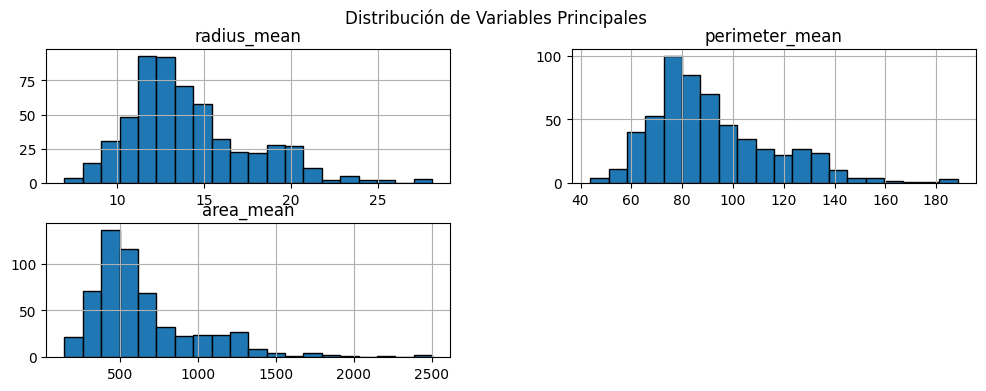

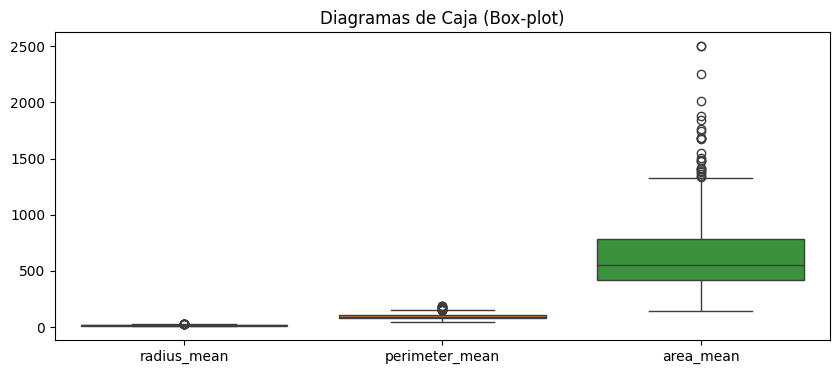

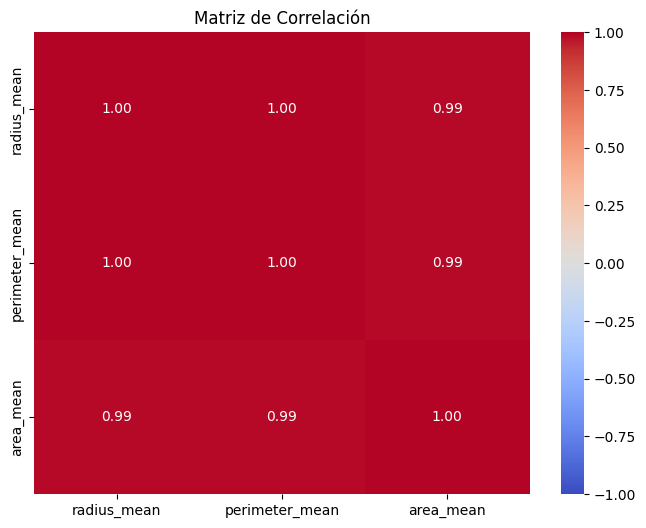

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar las variables de interés para el EDA
variables = ['radius_mean', 'perimeter_mean', 'area_mean']

# 1. Histogramas de distribución
df[variables].hist(bins=20, figsize=(12, 4), edgecolor='black')
plt.suptitle('Distribución de Variables Principales')
plt.show()

# 2. Box-plots para identificar la dispersión y posibles valores atípicos
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[variables])
plt.title('Diagramas de Caja (Box-plot)')
plt.show()

# 3. Gráfico de correlaciones (Matriz de correlación)
plt.figure(figsize=(8, 6))
sns.heatmap(df[variables].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlación')
plt.show()

In [7]:
from sklearn.linear_model import LinearRegression

# Definir X e y para el primer modelo
X1 = df[['radius_mean']] # Debe ser un DataFrame (2D)
y1 = df['perimeter_mean'] # Serie (1D)

# Inicializar y entrenar el modelo
modelo1 = LinearRegression()
modelo1.fit(X1, y1)

# Obtener pendiente e intercepto
print("--- Modelo 1: Perímetro vs Radio ---")
print(f"Pendiente (Coeficiente): {modelo1.coef_[0]:.4f}")
print(f"Intercepto: {modelo1.intercept_:.4f}")

--- Modelo 1: Perímetro vs Radio ---
Pendiente (Coeficiente): 6.8804
Intercepto: -5.2324


In [8]:
# Definir X e y para el segundo modelo
X2 = df[['radius_mean']]
y2 = df['area_mean']

# Inicializar y entrenar el segundo modelo
modelo2 = LinearRegression()
modelo2.fit(X2, y2)

print("--- Modelo 2: Área vs Radio ---")
print(f"Pendiente (Coeficiente): {modelo2.coef_[0]:.4f}")
print(f"Intercepto: {modelo2.intercept_:.4f}")

--- Modelo 2: Área vs Radio ---
Pendiente (Coeficiente): 98.5982
Intercepto: -738.0367


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

# 1. División para el Modelo 1 (Perímetro)
X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)
modelo1.fit(X_train1, y_train1)
y_pred1 = modelo1.predict(X_test1)

print("--- Métricas Modelo 1 (Perímetro) ---")
print(f"R²: {r2_score(y_test1, y_pred1):.4f}")
print(f"MAE: {mean_absolute_error(y_test1, y_pred1):.4f}")
print(
    f"RMSE: {np.sqrt(mean_squared_error(y_test1, y_pred1)):.4f}"
)  # O usa squared=False si tu scikit-learn es antiguo

# 2. División para el Modelo 2 (Área)
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)
modelo2.fit(X_train2, y_train2)
y_pred2 = modelo2.predict(X_test2)

print("\n--- Métricas Modelo 2 (Área) ---")
print(f"R²: {r2_score(y_test2, y_pred2):.4f}")
print(f"MAE: {mean_absolute_error(y_test2, y_pred2):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test2, y_pred2)):.4f}")

--- Métricas Modelo 1 (Perímetro) ---
R²: 0.9957
MAE: 1.0424
RMSE: 1.5834

--- Métricas Modelo 2 (Área) ---
R²: 0.9812
MAE: 34.9748
RMSE: 46.5776


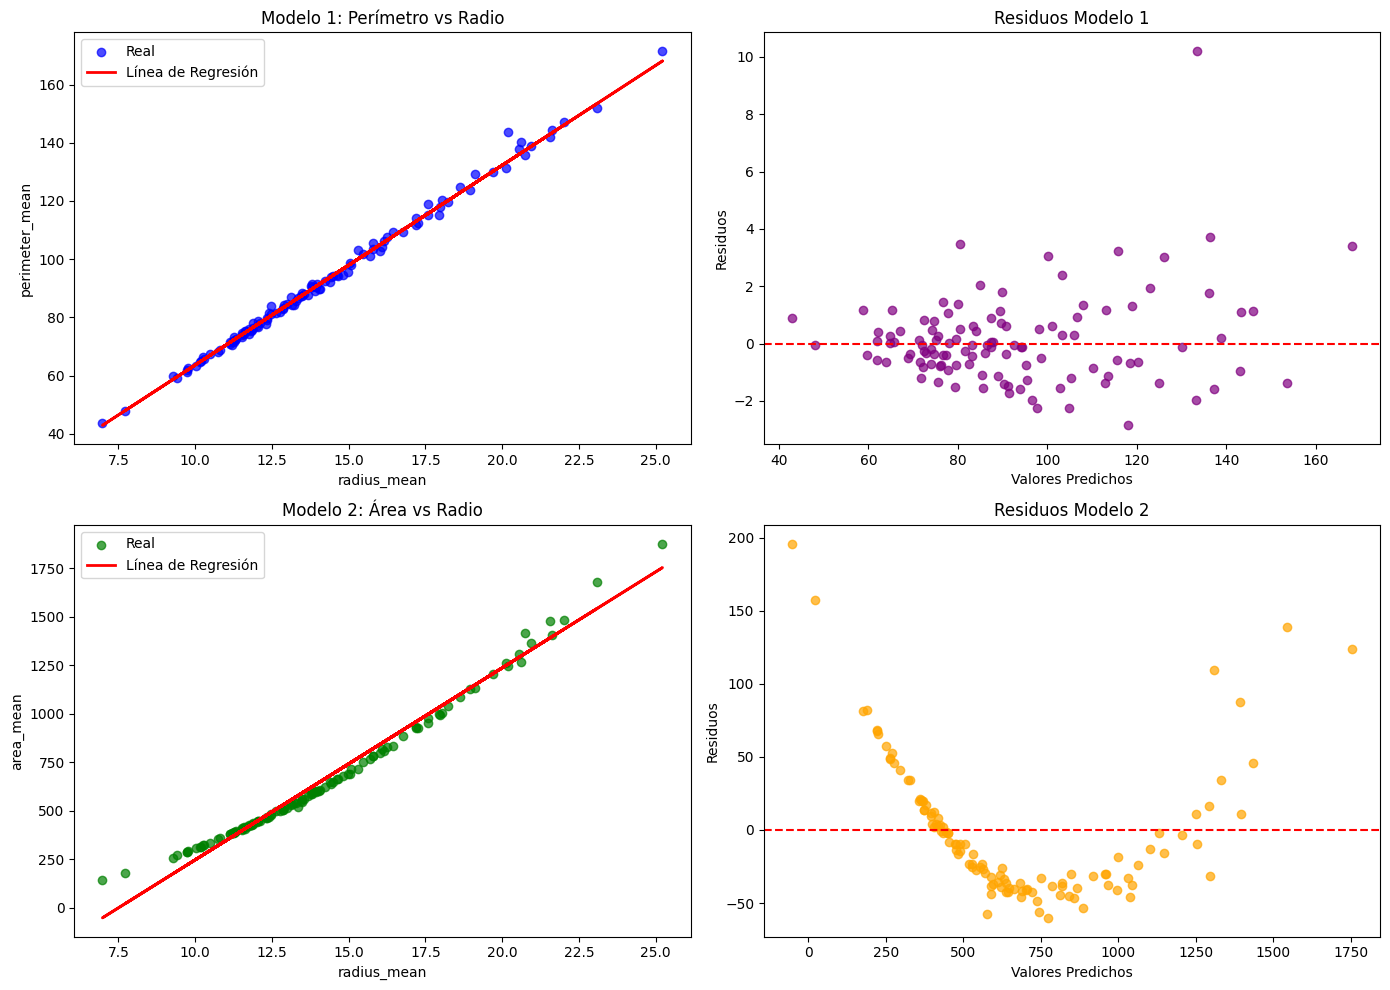

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Gráficos Modelo 1 ---
# 1. Regresión Modelo 1
axes[0, 0].scatter(X_test1, y_test1, color='blue', alpha=0.7, label='Real')
axes[0, 0].plot(
    X_test1, y_pred1, color='red', linewidth=2, label='Línea de Regresión'
)
axes[0, 0].set_title('Modelo 1: Perímetro vs Radio')
axes[0, 0].set_xlabel('radius_mean')
axes[0, 0].set_ylabel('perimeter_mean')
axes[0, 0].legend()

# 2. Residuos Modelo 1
residuos1 = y_test1 - y_pred1
axes[0, 1].scatter(y_pred1, residuos1, color='purple', alpha=0.7)
axes[0, 1].axhline(y=0, color='red', linestyle='--')
axes[0, 1].set_title('Residuos Modelo 1')
axes[0, 1].set_xlabel('Valores Predichos')
axes[0, 1].set_ylabel('Residuos')

# --- Gráficos Modelo 2 ---
# 3. Regresión Modelo 2
axes[1, 0].scatter(X_test2, y_test2, color='green', alpha=0.7, label='Real')
axes[1, 0].plot(
    X_test2, y_pred2, color='red', linewidth=2, label='Línea de Regresión'
)
axes[1, 0].set_title('Modelo 2: Área vs Radio')
axes[1, 0].set_xlabel('radius_mean')
axes[1, 0].set_ylabel('area_mean')
axes[1, 0].legend()

# 4. Residuos Modelo 2
residuos2 = y_test2 - y_pred2
axes[1, 1].scatter(y_pred2, residuos2, color='orange', alpha=0.7)
axes[1, 1].axhline(y=0, color='red', linestyle='--')
axes[1, 1].set_title('Residuos Modelo 2')
axes[1, 1].set_xlabel('Valores Predichos')
axes[1, 1].set_ylabel('Residuos')

plt.tight_layout()
plt.show()

### Pregunta guía: ¿Un R² alto es suficiente para concluir que una recta es el modelo adecuado?

**No, un $R^2$ alto por sí solo no es suficiente** para concluir que un modelo lineal es el adecuado. Aunque un coeficiente de determinación ($R^2$) cercano a 1 indica que el modelo explica una gran parte de la variabilidad de los datos, la evaluación visual de los **gráficos de residuos** es indispensable para validar los supuestos de la regresión lineal (como la linealidad y la homocedasticidad).

Esto se evidencia claramente al comparar nuestros dos modelos:

1. **Modelo 1 (Perímetro vs. Radio):** Presenta un $R^2$ extremadamente alto y, al revisar su gráfico de residuos, los puntos se distribuyen de forma aleatoria y uniforme alrededor de la línea horizontal en cero ($y=0$). Esto confirma que la relación subyacente es verdaderamente lineal y que la recta es un modelo adecuado.
2. **Modelo 2 (Área vs. Radio):** Aunque también puede arrojar un $R^2$ elevado debido a la fuerte correlación matemática, al observar su gráfico de residuos **se distingue claramente un patrón curvo**.

La presencia de este patrón en el gráfico de residuos del Modelo 2 demuestra que los errores no son aleatorios, revelando que la relación real entre las variables es de carácter cuadrático y no lineal. Por lo tanto, un $R^2$ alto puede ser engañoso si no se complementa con el análisis de residuos, que es el que verdaderamente nos indica si la forma funcional lineal es la correcta.